<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns-Building-Robust-and-Efficient-AI-Systems/blob/main/16.Interpretability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 16 -- Interpretability

*LLM Design Patterns*

**Technical edition (GPU Colab) -- kode buku yang sudah diperbaiki, ditambah eksperimen yang menguji klaim bab.**

Model bahasa bisa menjawab dengan benar tanpa memberi tahu *mengapa*. Bab ini mengumpulkan perkakas untuk mengintip ke dalamnya, dan satu pertanyaan kita bawa sampai akhir: **apakah penjelasan dari sebuah perkakas benar-benar mencerminkan cara model bekerja?**

Listing buku yang tidak bisa jalan apa adanya tidak dijadikan sel kode. Cuplikan dan penjelasan error-nya ada di kotak **Listing buku**; sel sesudahnya berisi versi yang bekerja. Bagian **Under the hood** adalah eksperimen tambahan:

| Under the hood | Pertanyaannya | Hasil |
|---|---|---|
| UTH-1: probe lawan kontrol | Apakah BERT *mempelajari* sifat bahasa? | Panjang kalimat terbaca sama baiknya dari BERT acak; urutan kata tidak |
| UTH-2: kepercayaan integrated gradients (IG) | Kapan skor pentingnya kata dari IG berubah? | Tidak saat dijalankan ulang; berubah besar bila titik netralnya atau modelnya diganti |
| UTH-3: atensi lawan atribusi | Apakah token yang paling diperhatikan menentukan prediksi? | Tidak lebih baik dari token acak; menghapus token pilihan IG berdampak hampir dua kali lipat |
| UTH-4: induction head GPT-2 | Head mana yang membuat GPT-2 menyalin teks? | Menolkan 6 head hampir menghapus kemampuan menyalin; 6 head acak tidak |

> **Sebelum menjalankan.** Pilih runtime GPU dulu: Runtime > Change runtime type > Hardware accelerator: T4 GPU (atau GPU lain yang tersedia) > Save, lalu Runtime > Run all. Sel setup menguji GPU dengan perhitungan sungguhan dan berhenti dengan petunjuk bila GPU belum siap. CPU hanya dipakai bila Anda sendiri mengubah `USE_CPU = True`; Run all di CPU bisa lebih dari satu jam. Token akses Hugging Face (`HF_TOKEN`) tidak diperlukan karena semua model dan data publik, dan peringatan *unauthenticated requests* boleh diabaikan.
>
> **Asal angka.** Edisi GPU ini belum pernah dijalankan di GPU CUDA atau di Colab sungguhan. Angka yang dikutip narasi berasal dari run acuan di CPU (Mac M1 Pro, versi paket runtime Colab Oktober 2026). Bagian yang tidak melatih model (16.1, 16.2, UTH-1, awal 16.3, 16.4, 16.5, UTH-4) seharusnya memberi angka yang sama atau bergeser di desimal terakhir. Bagian yang memakai BERT hasil fine-tuning (sisa 16.3, UTH-2, UTH-3, 16.6) akan memberi angka sendiri, karena pelatihan di perangkat lain menghasilkan model yang sedikit berbeda; di sana narasi menyebut angka "run acuan", dan yang perlu Anda cocokkan adalah polanya.

In [1]:
# Colab sudah menyediakan semua paket bab ini. pip hanya dipanggil bila ada yang hilang atau terlalu lama
# (misalnya saat notebook dijalankan di luar Colab).
import importlib.util
import re
import subprocess
import sys
from importlib.metadata import version

PACKAGES = {"torch": "torch", "transformers": "transformers", "datasets": "datasets", "accelerate": "accelerate",
            "sklearn": "scikit-learn", "scipy": "scipy", "seaborn": "seaborn", "matplotlib": "matplotlib",
            "pandas": "pandas"}
MINIMUM = {"transformers": "4.46", "accelerate": "1.1"}   # Trainer(processing_class=...) dan kebutuhan Trainer


def major_minor(text):
    return tuple(int(part) for part in re.findall(r"\d+", text)[:2])


to_install = []
for module, dist in PACKAGES.items():
    if importlib.util.find_spec(module) is None:
        to_install.append(f"{dist}>={MINIMUM[dist]}" if dist in MINIMUM else dist)
    elif dist in MINIMUM and major_minor(version(dist)) < major_minor(MINIMUM[dist]):
        to_install.append(f"{dist}>={MINIMUM[dist]}")
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
    if any(module in sys.modules for module in PACKAGES):
        print("Paket diperbarui setelah sempat diimpor: restart runtime, lalu jalankan ulang dari atas.")
print("paket yang diinstal:", to_install or "tidak ada, semuanya sudah tersedia")

paket yang diinstal: tidak ada, semuanya sudah tersedia


In [2]:
# Edisi GPU: notebook ini meminta GPU CUDA. CPU hanya dipakai bila Anda memilihnya sendiri,
# karena Run all di CPU bisa memakan lebih dari satu jam.
import os
import torch

USE_CPU = False   # ganti ke True hanya bila memang ingin menjalankan semuanya di CPU

# CH16_DEVICE (cpu / mps / cuda) hanya untuk pengujian di luar Colab
requested = os.environ.get("CH16_DEVICE", "cpu" if USE_CPU else "cuda")


def check_cuda():
    """Pastikan GPU benar-benar bisa menghitung, bukan sekadar terdeteksi."""
    if not torch.cuda.is_available():
        raise RuntimeError(
            "GPU CUDA tidak tersedia. Di Colab: Runtime > Change runtime type > "
            "Hardware accelerator: T4 GPU (atau GPU lain) > Save, lalu Runtime > Run all. "
            "Bila sengaja ingin memakai CPU, set USE_CPU = True di sel ini.")
    probe = torch.randn(1024, 1024, device="cuda")
    product = probe @ probe
    torch.cuda.synchronize()
    if not torch.isfinite(product).all():
        raise RuntimeError("GPU terdeteksi, tetapi uji perkalian matriks gagal. "
                           "Runtime > Restart session, lalu Run all.")
    del probe, product
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info()
    return torch.cuda.get_device_properties(0), free, total


if requested.startswith("cuda"):
    gpu, free, total = check_cuda()
    DEVICE = torch.device("cuda")
    print(f"GPU siap: {gpu.name} | compute capability {gpu.major}.{gpu.minor} | "
          f"memori bebas {free / 1e9:.1f} dari {total / 1e9:.1f} GB")
    print(f"BF16 native: {'ya' if torch.cuda.is_bf16_supported(including_emulation=False) else 'tidak'} | "
          "notebook ini memakai float32 di semua perangkat")
else:
    DEVICE = torch.device(requested)
    print(f"device: {DEVICE} (dipilih eksplisit, bukan GPU CUDA; Run all akan jauh lebih lambat)")

GPU siap: Tesla T4 | compute capability 7.5 | memori bebas 15.5 dari 15.6 GB
BF16 native: tidak | notebook ini memakai float32 di semua perangkat


Kalau sel di atas mencetak nama GPU, misalnya *Tesla T4*, berarti GPU sudah diuji dengan perkalian matriks sungguhan, bukan sekadar terdeteksi. Memori bebasnya adalah ruang kerja Anda (T4 sekitar 15 GB); berapa yang benar-benar terpakai dicetak di baris terakhir 16.6. Kalau yang muncul pesan *GPU CUDA tidak tersedia*, ganti runtime dulu lalu Run all lagi.

Baris kedua menyebut apakah GPU mendukung **BF16**, format angka 16-bit yang mempercepat pelatihan dengan ketelitian lebih rendah. T4 tidak mendukungnya secara native, dan agar hasilnya sebanding di GPU mana pun notebook ini selalu memakai **float32**: format 32-bit yang sama dengan run acuan, sehingga gradien untuk atribusi seteliti versi CPU. Beberapa langkah sengaja tetap di CPU: probe scikit-learn (16.2, UTH-1), model mainan 16.5, selang kepercayaan di UTH-3, dan semua grafik.

In [3]:
import gc
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch.nn as nn
import torch.nn.functional as F
import datasets
import transformers
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()


def load_hf_token():
    """HF_TOKEN opsional: dari Colab Secrets, lalu dari environment. Nilainya tak pernah dicetak."""
    try:
        from google.colab import userdata
        return userdata.get("HF_TOKEN")
    except Exception:  # bukan Colab, secret belum dibuat, atau akses notebook ke secret belum diizinkan
        return os.environ.get("HF_TOKEN")


hf_token = load_hf_token()
if hf_token:
    os.environ["HF_TOKEN"] = hf_token
del hf_token


def sync():
    """Tunggu GPU selesai sebelum membaca jam: kerja CUDA berjalan asinkron."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def free_memory():
    """Bebaskan tensor yang sudah tak dipakai dan kembalikan cache GPU setelah sebuah eksperimen."""
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


def forget(*names):
    """Hapus variabel global yang tak dipakai lagi (aman bila sel dijalankan ulang), lalu bebaskan memori."""
    for name in names:
        globals().pop(name, None)
    free_memory()


torch.manual_seed(42)
token_status = "ada (tidak dicetak)" if os.environ.get("HF_TOKEN") else "tidak ada, unduhan publik anonim"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__}")
print(f"device: {DEVICE} | HF_TOKEN: {token_status}")

torch 2.11.0+cu130 | transformers 5.20.2 | datasets 4.8.5
device: cuda | HF_TOKEN: tidak ada, unduhan publik anonim


## 16.1 Visualisasi atensi

Di setiap lapisan transformer, tiap token mengumpulkan vektor dari semua token dalam kalimat dengan bobot yang berjumlah 1. Kalau `cat` memberi 0,4 ke `sat`, `sat` mendapat bobot 40% dalam campuran yang dikumpulkan `cat`. Susun bobot semua token dan kita mendapat **matriks atensi**: baris adalah token yang bertanya, kolom adalah token yang dipandang. Heatmap matriks inilah alat pertama buku.

> **Listing buku: `visualize_attention`**
>
> ```python
> outputs = model(inputs, output_attentions=True)
> attention = outputs.attentions[-1].squeeze().detach().numpy()
> sns.heatmap(attention, xticklabels=tokens, yticklabels=tokens, cmap="YlGnBu")
> ```
>
> Di transformers 5.18 (versi Colab saat ini) listing ini tersandung tiga kali:
>
> 1. `model(inputs)` menyerahkan seluruh dict keluaran tokenizer sebagai `input_ids`, dan BERT gagal dengan `AttributeError`. Perbaikannya `model(**inputs)`.
> 2. `outputs.attentions` lalu ternyata kosong (`IndexError: tuple index out of range`): implementasi atensi bawaan, `sdpa`, tidak mengembalikan bobotnya. Model perlu dimuat dengan `attn_implementation="eager"`.
> 3. Atensi lapisan terakhir berbentuk `(12, 9, 9)`, sedangkan heatmap butuh 2-D (`ValueError: Must pass 2-d input`). Sel di bawah merata-ratakan 12 matriks 9 x 9 itu menjadi satu.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


bentuk atensi lapisan terakhir: (12, 9, 9)


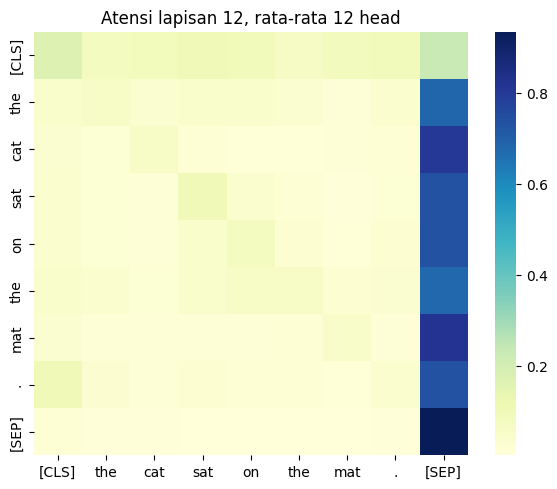

In [4]:
from transformers import BertModel, BertTokenizer

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert = BertModel.from_pretrained("bert-base-uncased", attn_implementation="eager").to(DEVICE).eval()


def visualize_attention(model, tokenizer, text):
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)
    attention = outputs.attentions[-1][0]          # lapisan terakhir: (head, query, key)
    print("bentuk atensi lapisan terakhir:", tuple(attention.shape))
    attention = attention.mean(dim=0).cpu().numpy()  # rata-rata 12 head menjadi satu matriks 2-D
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(attention, xticklabels=tokens, yticklabels=tokens, cmap="YlGnBu")
    plt.title("Atensi lapisan 12, rata-rata 12 head")
    plt.show()


text = "The cat sat on the mat."
visualize_attention(bert, tokenizer, text)

Bentuk `(12, 9, 9)` berarti ada 12 **head** atensi yang bekerja paralel di satu lapisan (dibahas lagi di 16.4), masing-masing dengan matriks 9 x 9. Sembilan tokennya adalah enam kata, titik, dan dua token khusus: `[CLS]` di awal dan `[SEP]` di akhir kalimat.

Heatmap-nya didominasi satu kolom, dan itu bukan kata: hampir setiap baris menaruh bobot terbesarnya pada `[SEP]`. Sel berikut mengukur seberapa besar, dan sejak lapisan mana.

In [5]:
cat_sentence = "The cat sat on the mat."
inputs = tokenizer(cat_sentence, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    cat_attentions = bert(**inputs, output_attentions=True).attentions

print("ke mana atensi pergi (rata-rata semua head dan semua token penanya):")
for layer in (1, 6, 12):
    received_att = cat_attentions[layer - 1][0].mean(dim=(0, 1)).cpu()   # kolom heatmap, dirata-rata
    print(f"  lapisan {layer:>2}: enam kata {received_att[1:-2].sum():.0%} | titik {received_att[-2]:.0%} | "
          f"[CLS] {received_att[0]:.0%} | [SEP] {received_att[-1]:.0%}")

ke mana atensi pergi (rata-rata semua head dan semua token penanya):
  lapisan  1: enam kata 53% | titik 11% | [CLS] 23% | [SEP] 13%
  lapisan  6: enam kata 28% | titik 5% | [CLS] 5% | [SEP] 62%
  lapisan 12: enam kata 20% | titik 3% | [CLS] 6% | [SEP] 71%


Di lapisan 1, enam kata masih menerima 53% atensi. Di lapisan 6, `[SEP]` sudah menerima 62%, dan di lapisan 12, lapisan yang digambar buku, 71%, sementara enam kata tinggal 20%.

Clark dkk. (2019) sudah melaporkan pola ini: head yang tak punya pekerjaan untuk sebuah token "memarkir" atensinya di `[SEP]`, token yang hampir tidak membawa isi. **Jadi bobot atensi yang besar belum tentu berarti token itu penting.** Apakah atensi menunjuk kata yang menentukan prediksi akan diuji di UTH-3, setelah kita punya model yang membuat prediksi.

## 16.2 Probing

Atensi memberi tahu ke mana token memandang, bukan apa yang diketahui model. Untuk itu buku memakai **probe**: classifier sederhana (di sini regresi logistik) yang membaca satu sifat bahasa dari vektor kalimat di sebuah lapisan, yaitu rata-rata vektor semua tokennya. Kalau probe sesederhana itu bisa menebak apakah struktur kalimat rumit dari vektor lapisan 6, informasinya pasti tersedia di sana.

Buku mengklaim sebuah hierarki: lapisan bawah menangkap identitas token dan sintaksis, lapisan tengah struktur kalimat, lapisan atas semantik.

> **Listing buku: `probe_bert_layers`**
>
> ```python
> outputs = model(inputs, output_hidden_states=True)
> ...
> texts = ["The cat sat on the mat.", "The dog chased the ball.", ...]
> labels = [0, 1, ...]  # e.g., 0 for simple, 1 for complex sentences
> ```
>
> - `model(inputs)` lagi, dengan `AttributeError` yang sama seperti di 16.1.
> - `...` bukan komentar, melainkan objek `Ellipsis` Python. Tokenizer menolaknya di elemen ketiga (`ValueError: text input must be of type str ...`), dan label "kompleks" tak pernah didefinisikan.

Data penggantinya datang dari tugas probing **SentEval** (Conneau dkk., 2018): sepuluh tugas, masing-masing berisi kalimat berlabel untuk satu sifat bahasa. Kita memakai enam di antaranya, dari yang dangkal seperti panjang kalimat sampai yang menuntut pemahaman seperti urutan klausa.

In [6]:
SENTEVAL = {"sentence_length": "permukaan", "bigram_shift": "sintaksis", "tree_depth": "sintaksis",
            "past_present": "semantik", "odd_man_out": "semantik", "coordination_inversion": "semantik"}
SENTEVAL_URL = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/{}.txt"
os.makedirs("data/senteval", exist_ok=True)


def load_senteval(task):
    path = f"data/senteval/{task}.txt"
    if not os.path.exists(path):
        urllib.request.urlretrieve(SENTEVAL_URL.format(task), path + ".part")
        os.replace(path + ".part", path)
    return pd.read_csv(path, sep="\t", header=None, names=["split", "label", "text"],
                       quoting=3, keep_default_na=False)


for task, kind in SENTEVAL.items():
    d = load_senteval(task)
    print(f"{task:<23} {kind:<10} {len(d):>7,} kalimat, {d.label.nunique()} kelas")

shift = load_senteval("bigram_shift")
print("\ncontoh bigram_shift berlabel I (dua kata bertukar):", shift[shift.label == "I"].text.iloc[0])

sentence_length         permukaan  119,988 kalimat, 6 kelas
bigram_shift            sintaksis  120,000 kalimat, 2 kelas
tree_depth              sintaksis  120,000 kalimat, 7 kelas
past_present            semantik   120,000 kalimat, 2 kelas
odd_man_out             semantik   120,000 kalimat, 2 kelas
coordination_inversion  semantik   120,006 kalimat, 2 kelas

contoh bigram_shift berlabel I (dua kata bertukar): A week she 'd been with the man , just a week , and she had survived barely the ups and downs .


Tiap tugas berisi sekitar 120 ribu kalimat. Contoh `bigram_shift` di atas memperlihatkan jenis soalnya: *survived barely* seharusnya *barely survived*, dan penutur asli langsung merasa janggal.

Untuk listing buku kita pakai `tree_depth`, yang memberi **kedalaman pohon parse** tiap kalimat: kedalaman paling banyak 6 kita sebut sederhana, paling sedikit 10 kompleks, masing-masing 200 kalimat. Kelima tugas lainnya menunggu di UTH-1.

In [7]:
tree = load_senteval("tree_depth")
tree = tree[tree.split == "tr"].assign(depth=lambda d: d.label.astype(int))
shallow = tree[tree.depth <= 6].sample(200, random_state=0)
deep = tree[tree.depth >= 10].sample(200, random_state=0)
sample = pd.concat([shallow, deep]).sample(frac=1, random_state=0)
texts = list(sample.text)
labels = list((sample.depth >= 10).astype(int))

print(f"sederhana (kedalaman {shallow.depth.iloc[0]}): {shallow.text.iloc[0]}")
print(f"kompleks  (kedalaman {deep.depth.iloc[0]}): {deep.text.iloc[0]}")
print(f"rata-rata panjang: sederhana {shallow.text.str.split().str.len().mean():.1f} kata, "
      f"kompleks {deep.text.str.split().str.len().mean():.1f} kata")

sederhana (kedalaman 5): " Cattle , Rabbit , " Longbow said , " not exactly pets .
kompleks  (kedalaman 10): Harold suppressed the urge to grab the man by the collar and simply pointed at the dead light bulb .
rata-rata panjang: sederhana 12.8 kata, kompleks 13.9 kata


Kedalaman pohon mengukur seberapa bersarang struktur kalimat. Kalimat kompleks di atas menumpuk frasa di dalam frasa (*the urge to grab the man by the collar*), sedangkan yang sederhana hanya deretan potongan pendek. Panjang rata-ratanya nyaris sama, 12,8 lawan 13,9 kata, jadi probe tidak bisa "curang" dengan menghitung kata.

Fungsi buku di bawah hanya butuh `model(**inputs)`, ditambah `.to(model.device)` dan `.cpu()` agar ikut berjalan di GPU.

In [8]:
def probe_bert_layers(model, tokenizer, texts, labels, layer_nums):
    # Get BERT embeddings for each layer
    def get_embeddings(text):
        inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True).to(model.device)
        with torch.no_grad():
            outputs = model(**inputs, output_hidden_states=True)
        return outputs.hidden_states

    results = {}
    for layer in layer_nums:
        embeddings = [get_embeddings(text)[layer].squeeze().mean(dim=0).cpu().numpy() for text in texts]
        # Split data
        X_train, X_test, y_train, y_test = train_test_split(
            embeddings, labels, test_size=0.2, random_state=42
        )
        # Train and evaluate probe
        probe = LogisticRegression(random_state=42)
        probe.fit(X_train, y_train)
        y_pred = probe.predict(X_test)
        results[f"Layer_{layer}"] = accuracy_score(y_test, y_pred)
    return results


start = time.time()
probe_results = probe_bert_layers(bert, tokenizer, texts, labels, layer_nums=[1, 6, 12])
for layer, accuracy in probe_results.items():
    print(f"{layer} Accuracy: {accuracy:.2f}")
print(f"({time.time() - start:.0f} detik)")

Layer_1 Accuracy: 0.84
Layer_6 Accuracy: 0.90
Layer_12 Accuracy: 0.82
(29 detik)


Sekilas, pola buku muncul: akurasi tertinggi di lapisan 6 (0,90), lebih rendah di lapisan 1 (0,84) dan 12 (0,82). Tinggi atau rendah? Sel berikut menghitung dua pembanding: **tebakan mayoritas**, yaitu akurasi bila selalu menebak kelas yang paling sering, dan probe yang hanya diberi panjang kalimat.

In [9]:
_, _, y_train, y_test = train_test_split(texts, labels, test_size=0.2, random_state=42)
lengths = np.array([[len(t.split())] for t in texts])
len_train, len_test = train_test_split(lengths, test_size=0.2, random_state=42)
length_only = LogisticRegression().fit(len_train, y_train).score(len_test, y_test)

print(f"kalimat uji: {len(y_test)}")
print(f"tebakan mayoritas: {max(np.mean(y_test), 1 - np.mean(y_test)):.2f}")
print(f"probe yang hanya melihat panjang kalimat: {length_only:.2f}")

kalimat uji: 80
tebakan mayoritas: 0.50
probe yang hanya melihat panjang kalimat: 0.53


Tebakan mayoritas hanya 0,50, dan probe panjang kalimat 0,53. Jadi vektor BERT memang memuat sinyal yang membedakan kalimat dangkal dan dalam, dan sinyal itu bukan sekadar panjang kalimat.

Tapi "puncak di tengah" belum terbaca dari tiga angka ini. Dengan 80 kalimat uji, satu kalimat bernilai 1,25 poin, jadi selisih 6-8 poin antar-lapisan setara lima sampai enam kalimat saja, masih bisa kebetulan. Menguji hierarki buku butuh semua lapisan, lebih banyak tugas, data uji lebih besar, dan kontrol.

### Under the hood (UTH-1): hierarki lapisan, atau kapasitas probe?

Probe yang berhasil membuktikan informasinya *ada*, belum membuktikan model *mempelajarinya*. Jaringan berbobot acak pun mengubah kata menjadi vektor, dan sifat seperti panjang kalimat bisa ikut terbawa tanpa pelatihan.

Jadi kita butuh **kontrol**: BERT dengan arsitektur sama persis tetapi bobotnya acak. Keenam tugas SentEval di-probe di 13 representasi (embedding plus 12 lapisan) untuk kedua model, dengan 600 kalimat uji per tugas, cukup untuk membuat akurasi hanya bergeser sekitar 2 poin bila diulang.

In [10]:
from transformers import BertConfig

torch.manual_seed(0)
bert_random = BertModel(BertConfig.from_pretrained("bert-base-uncased")).to(DEVICE).eval()


@torch.no_grad()
def layer_means(model, sentences, batch_size=64):
    """Rata-rata vektor token di 13 representasi (embedding + 12 lapisan), seperti fungsi buku."""
    chunks = []
    for start in range(0, len(sentences), batch_size):
        enc = tokenizer(list(sentences[start:start + batch_size]), return_tensors="pt",
                        padding=True, truncation=True, max_length=64).to(model.device)
        hidden = model(**enc, output_hidden_states=True).hidden_states
        mask = enc["attention_mask"].unsqueeze(-1).float()
        chunks.append(torch.stack([(h * mask).sum(1) / mask.sum(1) for h in hidden], dim=1).cpu())
    return torch.cat(chunks).numpy()


def probe_curve(X_train, y_train, X_test, y_test):
    curve = []
    for layer in range(X_train.shape[1]):
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
        probe.fit(X_train[:, layer], y_train)
        curve.append(probe.score(X_test[:, layer], y_test))
    return np.array(curve)


N_TRAIN, N_TEST = 1500, 600   # per tugas; data penuh SentEval 100 ribu latih / 10 ribu uji
curves, senteval_majority = {}, {}
feature_seconds, probe_seconds = 0.0, 0.0
for task in SENTEVAL:
    d = load_senteval(task)
    train = d[d.split == "tr"].sample(N_TRAIN, random_state=0)
    test = d[d.split == "te"].sample(N_TEST, random_state=0)
    senteval_majority[task] = test.label.value_counts(normalize=True).iloc[0]
    for name, net in (("BERT", bert), ("acak", bert_random)):
        start = time.time()
        X_train = layer_means(net, train.text.values)
        X_test = layer_means(net, test.text.values)
        feature_seconds += time.time() - start
        start = time.time()
        curves[task, name] = probe_curve(X_train, train.label, X_test, test.label)   # scikit-learn: selalu di CPU
        probe_seconds += time.time() - start
del bert_random, net
free_memory()

print(f"fitur BERT di {DEVICE}: {feature_seconds:.0f} detik | probe scikit-learn di CPU: {probe_seconds:.0f} detik\n")
print(f"{'tugas':<23} {'lantai':>6} {'BERT L0':>8} {'BERT puncak':>12} {'BERT L12':>9} {'acak di puncak':>15}")
for task in SENTEVAL:
    bert_curve, random_curve = curves[task, "BERT"], curves[task, "acak"]
    best = int(bert_curve.argmax())
    print(f"{task:<23} {senteval_majority[task]:>6.2f} {bert_curve[0]:>8.2f} {bert_curve[best]:>6.2f} (L{best:<2}) "
          f"{bert_curve[12]:>9.2f} {random_curve[best]:>15.2f}")

fitur BERT di cuda: 45 detik | probe scikit-learn di CPU: 174 detik

tugas                   lantai  BERT L0  BERT puncak  BERT L12  acak di puncak
sentence_length           0.19     0.85   0.85 (L0 )      0.53            0.85
bigram_shift              0.51     0.50   0.85 (L9 )      0.82            0.49
tree_depth                0.20     0.25   0.30 (L6 )      0.25            0.24
past_present              0.51     0.74   0.83 (L11)      0.82            0.61
odd_man_out               0.51     0.51   0.60 (L11)      0.57            0.51
coordination_inversion    0.52     0.52   0.62 (L7 )      0.58            0.53


Kolom **lantai** adalah tebakan mayoritas tiap tugas. Tiga kolom BERT menunjukkan awal, puncak, dan akhir kurvanya; kolom terakhir adalah BERT acak di lapisan puncak itu. Baris pertama tabel sudah mengejutkan: untuk panjang kalimat, BERT acak menyamai BERT terlatih, sama-sama sekitar 0,85.

Puncak `tree_depth` 0,30 tidak bertentangan dengan 0,90 di 16.2. Soalnya kini menebak satu dari 7 kedalaman persis (lantai 0,20), bukan memisahkan dua kelompok ekstrem, dan di soal sesulit ini BERT terlatih hanya unggul tipis atas BERT acak (0,30 lawan 0,24).

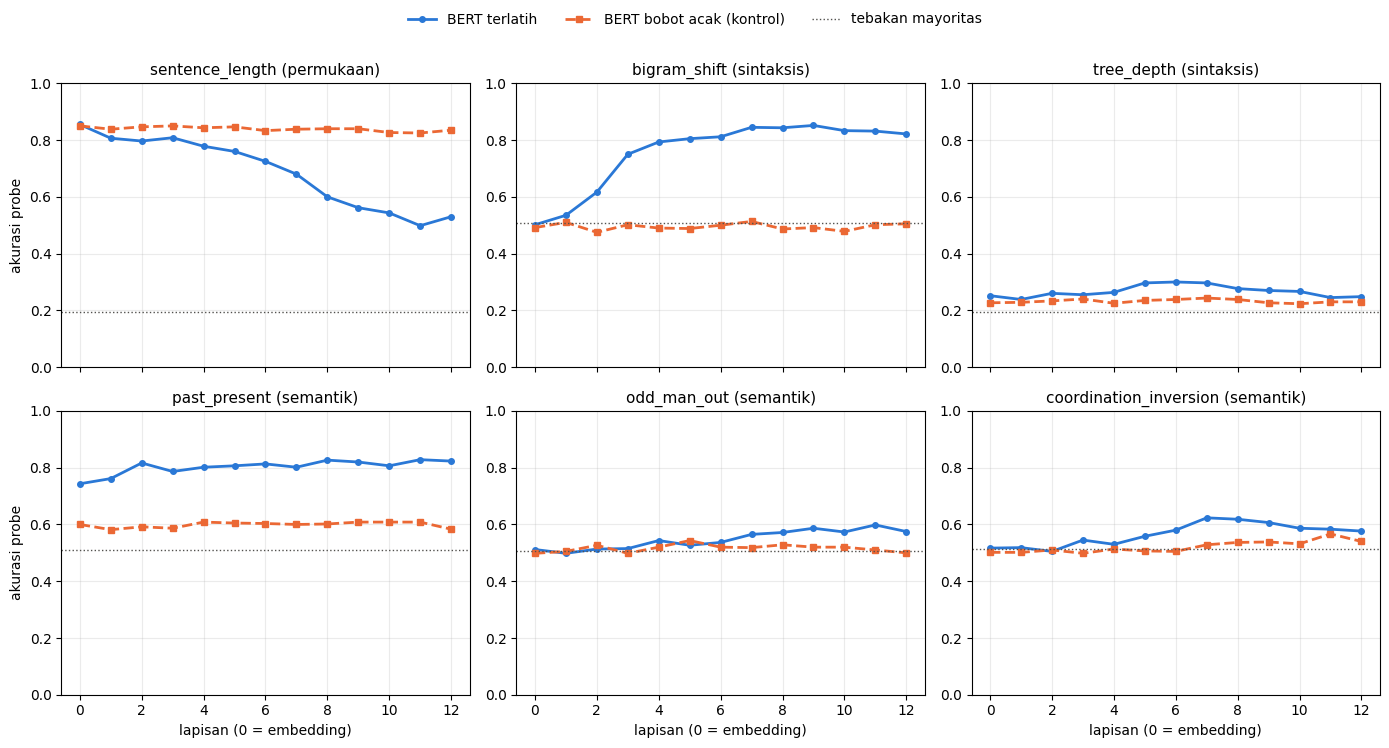

In [11]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
for ax, (task, kind) in zip(axs.ravel(), SENTEVAL.items()):
    ax.plot(range(13), curves[task, "BERT"], color="#2a78d6", lw=2, marker="o", ms=4, label="BERT terlatih")
    ax.plot(range(13), curves[task, "acak"], color="#eb6834", lw=2, ls="--", marker="s", ms=4,
            label="BERT bobot acak (kontrol)")
    ax.axhline(senteval_majority[task], color="#52514e", lw=1, ls=":", label="tebakan mayoritas")
    ax.set_title(f"{task} ({kind})", fontsize=11)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
for ax in axs[1]:
    ax.set_xlabel("lapisan (0 = embedding)")
for ax in axs[:, 0]:
    ax.set_ylabel("akurasi probe")
handles, names = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

**Informasi permukaan gratis.** Panjang kalimat paling jelas di embedding (0,85) lalu memudar ke 0,53 di lapisan 12. Tapi garis oranye datar di sekitar 0,85: jaringan acak pun membawanya, dan pelatihan BERT justru membuangnya di lapisan atas.

**Urutan kata dipelajari, mulai di lapisan bawah.** Deteksi dua kata tertukar setara undian di embedding (0,50), naik tajam di lapisan 2-3, lalu terus menguat sampai puncak 0,85 di lapisan 9, sementara BERT acak tertahan di 0,49. Ini sintaksis hasil belajar, dan soal letaknya buku hanya separuh benar: informasinya muncul di lapisan bawah, tetapi paling kuat di lapisan tengah-atas.

**"Semantik" tidak seragam.** Kala kerja (`past_present`) sudah 0,74 di embedding, dan BERT acak pun 0,61, kemungkinan karena akhiran seperti *-ed* melekat pada tokennya. Kata yang diam-diam diganti (`odd_man_out`) dan klausa yang ditukar (`coordination_inversion`) hanya mencapai 0,60-0,62, sekitar 10 poin di atas lantai.

Hierarki buku paling banter kecenderungan kasar. **Akurasi probe hanya bermakna di samping kontrol:** tanpa BERT acak, 0,85 untuk panjang kalimat akan terbaca sebagai "BERT mempelajari panjang kalimat".

## 16.3 Atribusi dengan integrated gradients

Pertanyaan berikutnya lebih tajam: untuk satu prediksi, **kata mana yang paling menentukan?** Inilah **atribusi**, dan buku memilih **integrated gradients (IG)**.

Bayangkan kata *fantastic* dimunculkan perlahan dari titik netral, yang disebut **baseline** (misalnya token `[PAD]`), sampai utuh. Di tiap langkah kita catat seberapa peka keluaran model terhadap kata itu, yaitu gradiennya. Rata-rata kepekaan sepanjang jalan, dikalikan jarak kata itu dari baseline, menjadi atribusinya.

> **Listing buku: `integrated_gradients`**
>
> ```python
> baseline_ids = torch.zeros_like(input_ids)
> interpolated_ids = baseline_ids + alpha * delta
> outputs = model(interpolated_ids)
> ...
> model = BertForSequenceClassification.from_pretrained(model_name)
> target_class = 1  # Assuming 1 is the positive sentiment class
> ```
>
> - Listing ini memudarkan **nomor ID token**, bukan vektor maknanya. Hasil interpolasinya bertipe float, dan lapisan embedding menolaknya sejak langkah pertama: `RuntimeError: Expected tensor for argument #1 'indices' to have one of the following scalar types: Long, Int; but got torch.FloatTensor instead`. Dibulatkan pun tidak menolong, seperti ditunjukkan sel berikut.
> - `from_pretrained("bert-base-uncased")` memasang **kepala klasifikasi** baru (lapisan linear yang mengubah vektor `[CLS]` menjadi skor tiap kelas) berbobot acak. Model itu belum pernah belajar sentimen, jadi "kelas 1 = positif" hanya harapan.

In [12]:
fantastic_id = tokenizer.convert_tokens_to_ids("fantastic")
print(f"[PAD] = ID 0, 'fantastic' = ID {fantastic_id}")
print(f"titik tengah garis ID = ID {fantastic_id // 2} = {tokenizer.convert_ids_to_tokens(fantastic_id // 2)!r}")

[PAD] = ID 0, 'fantastic' = ID 10392
titik tengah garis ID = ID 5196 = 'arena'


Titik tengah garis dari `[PAD]` ke *fantastic* di ruang ID adalah kata *arena*. Nomor ID hanyalah urutan di kosakata tokenizer; ID yang berdekatan bukan kata yang mirip. Garis lurus baru bermakna di **ruang embedding**, tempat jarak mencerminkan makna, dan di sanalah IG versi kita akan bekerja.

Masalah kedua ada pada modelnya. Untuk mengujinya kita butuh kalimat berlabel sentimen: **SST-2**, kalimat ulasan film berlabel positif atau negatif.

In [13]:
sst_train = load_dataset("nyu-mll/glue", "sst2", split="train")
sst_val = load_dataset("nyu-mll/glue", "sst2", split="validation")
VAL_TEXTS = [s.strip() for s in sst_val["sentence"]]
VAL_LABELS = np.array(sst_val["label"])
SST2_MAJORITY = max(VAL_LABELS.mean(), 1 - VAL_LABELS.mean())
print(f"SST-2: {len(sst_train):,} kalimat latih, {len(VAL_TEXTS)} kalimat validasi, "
      f"{VAL_LABELS.mean():.1%} positif")

SST-2: 67,349 kalimat latih, 872 kalimat validasi, 50.9% positif


Validasi SST-2 berisi 872 kalimat, 50,9% positif, jadi model malas yang selalu menjawab "positif" sudah benar pada 50,9% kalimat. Tebakan mayoritas ini adalah lantai: model yang tidak melampauinya belum layak dijelaskan.

In [14]:
from transformers import BertForSequenceClassification


@torch.no_grad()
def predict_proba(model, sentences, batch_size=64):
    model.eval()
    probs = []
    for start in range(0, len(sentences), batch_size):
        enc = tokenizer(list(sentences[start:start + batch_size]), return_tensors="pt",
                        padding=True, truncation=True, max_length=128).to(model.device)
        if model.config.model_type == "distilbert":
            enc.pop("token_type_ids")  # DistilBERT tidak memakai segment embedding
        probs.append(F.softmax(model(**enc).logits, dim=-1).cpu())
    return torch.cat(probs).numpy()


torch.manual_seed(0)
book_model = BertForSequenceClassification.from_pretrained("bert-base-uncased").to(DEVICE)
p_book = predict_proba(book_model, VAL_TEXTS)
print(f"kepala klasifikasi baru: akurasi {np.mean(p_book.argmax(1) == VAL_LABELS):.3f}, "
      f"menebak positif {np.mean(p_book.argmax(1)):.1%}")
print(f"tebakan mayoritas: {SST2_MAJORITY:.3f}")
del book_model
free_memory()

kepala klasifikasi baru: akurasi 0.491, menebak positif 0.7%
tebakan mayoritas: 0.509


Kepala acak buku menebak "positif" untuk 0,7% kalimat saja, dengan akurasi 0,491, di bawah lantai 0,509. Menjelaskan model seperti ini sama dengan menjelaskan noise, jadi kita fine-tune BERT pada 2.000 kalimat SST-2.

In [15]:
from transformers import Trainer, TrainingArguments
from transformers.trainer_callback import PrinterCallback


def finetune_bert(texts, labels, seed=0):
    transformers.set_seed(seed)
    model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2,
                                                          attn_implementation="eager")
    train_ds = datasets.Dataset.from_dict({"text": texts, "label": labels}).map(
        lambda batch: tokenizer(batch["text"], truncation=True, max_length=128),
        batched=True, remove_columns=["text"])
    args = TrainingArguments(output_dir="results_ft", num_train_epochs=1, learning_rate=2e-5,
                             per_device_train_batch_size=16, save_strategy="no", logging_strategy="no",
                             report_to="none", disable_tqdm=True, seed=seed,
                             use_cpu=DEVICE.type == "cpu", dataloader_pin_memory=DEVICE.type == "cuda")
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, processing_class=tokenizer)
    trainer.remove_callback(PrinterCallback)
    trainer.train()
    sync()
    del trainer   # lepaskan optimizer AdamW dan gradiennya dari memori GPU
    free_memory()
    return model.to(DEVICE).eval()


subset = sst_train.shuffle(seed=0).select(range(2000))
start = time.time()
clf = finetune_bert([s.strip() for s in subset["sentence"]], list(subset["label"]))
p_clf = predict_proba(clf, VAL_TEXTS)
print(f"fine-tuning 2.000 kalimat, 1 epoch: {time.time() - start:.0f} detik")
print(f"akurasi validasi {np.mean(p_clf.argmax(1) == VAL_LABELS):.3f}, menebak positif {np.mean(p_clf.argmax(1)):.1%}")

fine-tuning 2.000 kalimat, 1 epoch: 17 detik
akurasi validasi 0.861, menebak positif 49.2%


Satu epoch sudah cukup untuk akurasi sekitar 0,87 (run acuan 0,875), jauh di atas lantai 0,509. Model `clf` inilah yang kita jelaskan di sisa 16.3, UTH-2, dan UTH-3, dan nanti menjadi guru di 16.6.

### IG di ruang embedding

Sekarang IG bisa dijalankan dengan benar. Skemanya tetap skema buku, 50 titik dari baseline sampai input termasuk kedua ujungnya, tetapi yang dipudarkan adalah vektor embedding tiap kata, bukan nomor ID-nya. `[CLS]` dan `[SEP]` dibiarkan utuh.

p(positif) = 0.886
[CLS] +0.00  this -0.64  movie -0.05  was +0.19  fantastic +3.17  ! -0.34  [SEP] +0.00
jumlah atribusi +2.333 vs selisih logit input - baseline +2.049


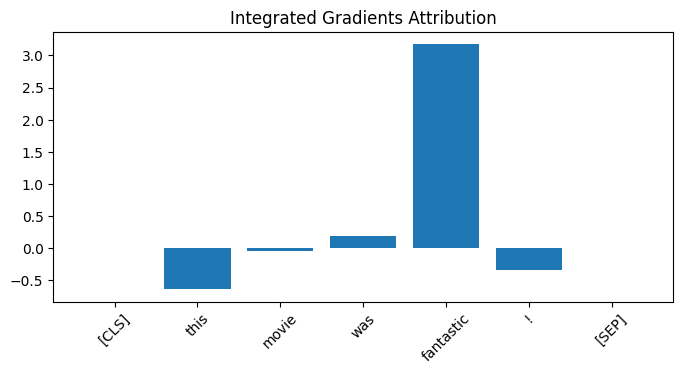

In [16]:
def integrated_gradients(model, tokenizer, text, target_class, steps=50, baseline="pad", chunk=50):
    """IG di ruang embedding: garis lurus dari embedding baseline ke embedding input."""
    enc = tokenizer(text, return_tensors="pt").to(model.device)
    ids = enc["input_ids"]
    embed = model.bert.embeddings.word_embeddings
    x = embed(ids).detach()
    if baseline == "zero":
        x_base = torch.zeros_like(x)
    else:
        base_id = tokenizer.pad_token_id if baseline == "pad" else tokenizer.mask_token_id
        x_base = embed(torch.full_like(ids, base_id)).detach()
    special = (ids == tokenizer.cls_token_id) | (ids == tokenizer.sep_token_id)
    x_base = torch.where(special.unsqueeze(-1), x, x_base)   # [CLS] dan [SEP] tidak ikut dipudarkan

    def target_logit(embeds):
        n = len(embeds)
        return model(inputs_embeds=embeds,
                     attention_mask=enc["attention_mask"].expand(n, -1),
                     token_type_ids=enc["token_type_ids"].expand(n, -1)).logits[:, target_class]

    alphas = torch.linspace(0, 1, steps, device=x.device)   # skema buku: kedua ujung ikut, lalu dibagi steps
    grad_sum = torch.zeros_like(x[0])
    for i in range(0, steps, chunk):
        a = alphas[i:i + chunk].view(-1, 1, 1)
        path = (x_base + a * (x - x_base)).requires_grad_(True)
        grad_sum += torch.autograd.grad(target_logit(path).sum(), path)[0].sum(0)
    attributions = ((x - x_base)[0] * grad_sum / steps).sum(-1)   # satu angka per token
    with torch.no_grad():
        gap = (target_logit(x) - target_logit(x_base)).item()    # completeness: jumlah atribusi seharusnya = gap
    return attributions.detach().cpu().numpy(), gap


text = "This movie was fantastic!"
target_class = 1  # pada model fine-tuned, kelas 1 memang positif (label SST-2)
attributions, gap = integrated_gradients(clf, tokenizer, text, target_class)
ig_tokens = tokenizer.convert_ids_to_tokens(tokenizer.encode(text))
print(f"p(positif) = {predict_proba(clf, [text])[0, 1]:.3f}")
print("  ".join(f"{tok} {value:+.2f}" for tok, value in zip(ig_tokens, attributions)))
print(f"jumlah atribusi {attributions.sum():+.3f} vs selisih logit input - baseline {gap:+.3f}")

plt.figure(figsize=(8, 3.5))
plt.bar(range(len(ig_tokens)), attributions)
plt.xticks(range(len(ig_tokens)), ig_tokens, rotation=45)
plt.title("Integrated Gradients Attribution")
plt.show()

Di run acuan, model yakin kalimat buku positif (p = 0,936), dan IG menunjuk alasannya: *fantastic* menyumbang +3,35, jauh di atas token lain. Nilai negatif seperti *this* (-0,89) berarti token itu menarik prediksi menjauh dari kelas positif.

Angka-angka ini bisa Anda periksa sendiri. IG punya sifat bernama **completeness**: jumlah atribusi semua token harus sama dengan selisih **logit** (skor mentah sebelum menjadi probabilitas) antara input dan baseline. Bandingkan dua angka di baris terakhir output; di run acuan +1,900 lawan +1,965, meleset sekitar 3%.

In [17]:
for sentence in ("The acting was superb, but the plot was confusing.", "I hated every minute of it."):
    probs = predict_proba(clf, [sentence])[0]
    pred_class = int(probs.argmax())
    attr, gap = integrated_gradients(clf, tokenizer, sentence, pred_class)
    sentence_tokens = tokenizer.convert_ids_to_tokens(tokenizer.encode(sentence))
    print(f"{sentence!r} -> {'positif' if pred_class else 'negatif'} (p = {probs[pred_class]:.3f})")
    print("   " + "  ".join(f"{tok} {value:+.2f}" for tok, value in zip(sentence_tokens[1:-1], attr[1:-1])))
    print(f"   jumlah {attr.sum():+.3f} vs selisih logit {gap:+.3f}\n")

'The acting was superb, but the plot was confusing.' -> negatif (p = 0.812)
   the +0.08  acting -0.02  was +0.11  superb -0.12  , +0.15  but +0.12  the +0.04  plot -0.01  was +0.15  confusing +0.12  . -0.07
   jumlah +0.549 vs selisih logit +0.183

'I hated every minute of it.' -> negatif (p = 0.913)
   i -0.08  hated -0.13  every +0.24  minute +0.03  of +0.19  it +0.34  . -0.04
   jumlah +0.563 vs selisih logit +0.582



Di sel ini IG menjelaskan kelas yang ditebak model, jadi nilai positif berarti mendukung tebakan itu. Di run acuan, *hated* menyumbang +0,65 untuk tebakan negatif pada *I hated every minute of it*.

Ulasan campuran lebih menarik. Model menebaknya negatif dengan p hanya 0,548, *superb* menarik menjauh dari negatif (-0,21), dan *confusing*, kata paling negatif menurut intuisi kita, nyaris nol (-0,03). Sifat model, akibat pilihan baseline, atau kebetulan satu kali pelatihan? Buku sendiri memperingatkan bahwa atribusi IG bisa tidak konsisten antar-run, dan UTH-2 memeriksanya, termasuk mengapa angka per kata di output Anda bisa berbeda jauh dari ini.

### Under the hood (UTH-2): seberapa bisa dipercaya angka IG?

Dua puluh kalimat SST-2, empat pertanyaan, satu per sel: berapa langkah yang cukup, seberapa besar pengaruh baseline, apakah IG berubah bila dijalankan ulang, dan apakah ia berubah bila modelnya dilatih ulang.

In [18]:
ig_sentences = [s.strip() for s in sst_val.shuffle(seed=1).select(range(20))["sentence"]]
ig_classes = [int(predict_proba(clf, [s])[0].argmax()) for s in ig_sentences]   # jelaskan tebakan model sendiri
reference_attr = {}                                    # IG baku: baseline [PAD], 50 langkah
completeness_miss = {10: [], 50: [], 200: []}

start = time.time()
for sentence, pred_class in zip(ig_sentences, ig_classes):
    for steps in completeness_miss:
        attr, gap = integrated_gradients(clf, tokenizer, sentence, pred_class, steps=steps)
        completeness_miss[steps].append(abs(attr.sum() - gap) / abs(gap))
        if steps == 50:
            reference_attr[sentence] = attr

print(f"{len(ig_sentences)} kalimat SST-2, {time.time() - start:.0f} detik")
print("completeness meleset (median | kalimat terburuk):")
for steps, miss in completeness_miss.items():
    print(f"  {steps:>3} langkah: {np.median(miss):6.1%} | {np.max(miss):6.1%}")

20 kalimat SST-2, 14 detik
completeness meleset (median | kalimat terburuk):
   10 langkah:  44.4% | 316.4%
   50 langkah:   1.9% |  18.9%
  200 langkah:   0.4% |   6.0%


Di run acuan, 10 langkah membuat completeness meleset 28,4% untuk kalimat tipikal (median). Dengan 50 langkah, mediannya 1,0%, tetapi kalimat terburuk masih meleset 28,6%. Baru 200 langkah yang membuat semuanya rapi (paling buruk 3,2%). **50 langkah biasanya cukup, tetapi tidak selalu**, jadi besar melesetnya completeness layak dilaporkan bersama atribusinya.

In [19]:
from scipy.stats import spearmanr

WORD_SLICE = slice(1, -1)   # posisi token kata, tanpa [CLS] dan [SEP]


def compare_rankings(attr_a, attr_b):
    """Korelasi Spearman antar-urutan pentingnya kata, dan apakah kata teratasnya sama."""
    rho = spearmanr(attr_a[WORD_SLICE], attr_b[WORD_SLICE]).correlation
    return rho, attr_a[WORD_SLICE].argmax() == attr_b[WORD_SLICE].argmax()


for label, baseline in (("vektor nol", "zero"), ("[MASK]", "mask")):
    rhos, same_top = [], []
    for sentence, pred_class in zip(ig_sentences, ig_classes):
        attr, _ = integrated_gradients(clf, tokenizer, sentence, pred_class, baseline=baseline)
        rho, same = compare_rankings(reference_attr[sentence], attr)
        rhos.append(rho)
        same_top.append(same)
    print(f"baseline [PAD] -> {label:<10}: Spearman rata-rata {np.nanmean(rhos):.2f}, "
          f"kata teratas tetap sama di {np.mean(same_top):.0%} kalimat")

baseline [PAD] -> vektor nol: Spearman rata-rata 0.26, kata teratas tetap sama di 35% kalimat
baseline [PAD] -> [MASK]    : Spearman rata-rata 0.25, kata teratas tetap sama di 50% kalimat


Korelasi **Spearman** membandingkan urutan pentingnya kata: 1 berarti urutannya sama persis, 0 berarti tak berhubungan.

Di run acuan, mengganti baseline `[PAD]` dengan vektor nol menyisakan korelasi 0,27, dan kata teratasnya sama hanya di 35% kalimat. Dengan `[MASK]`, 0,29 dan 55%. **Tiga baseline yang sama-sama sah memberi tiga jawaban berbeda.** IG tidak menjelaskan prediksi secara mutlak, melainkan selisihnya terhadap baseline yang kita pilih.

In [20]:
rerun_diff = []
for sentence, pred_class in zip(ig_sentences, ig_classes):
    again, _ = integrated_gradients(clf, tokenizer, sentence, pred_class)
    rerun_diff.append(np.abs(again - reference_attr[sentence]).max())

dropout_rho, dropout_same = [], []
clf.train()   # dropout aktif, seperti saat lupa memanggil .eval()
try:
    for sentence, pred_class in zip(ig_sentences, ig_classes):
        noisy, _ = integrated_gradients(clf, tokenizer, sentence, pred_class)
        rho, same = compare_rankings(reference_attr[sentence], noisy)
        dropout_rho.append(rho)
        dropout_same.append(same)
finally:
    clf.eval()

print(f"run ulang, mode eval : selisih atribusi terbesar {max(rerun_diff):.1e}")
print(f"run dengan dropout   : Spearman rata-rata {np.nanmean(dropout_rho):.2f}, "
      f"kata teratas sama di {np.mean(dropout_same):.0%} kalimat")

run ulang, mode eval : selisih atribusi terbesar 0.0e+00
run dengan dropout   : Spearman rata-rata 0.74, kata teratas sama di 75% kalimat


Dijalankan ulang pada model yang sama dalam mode eval, IG praktis identik: di run acuan selisihnya tepat 0, sedangkan di GPU bisa muncul selisih sekecil pembulatan float. Variasi baru muncul bila **dropout**, yang mematikan sebagian neuron secara acak dan seharusnya hanya aktif saat pelatihan, dibiarkan menyala karena lupa memanggil `.eval()`. Di run acuan korelasinya dengan run normal lalu turun ke 0,79.

Pertanyaan terakhir: bagaimana kalau modelnya sendiri berbeda? Sel berikut melatih model kedua dengan resep yang sama persis, hanya seed acaknya diganti.

In [21]:
# model kedua: resep fine-tuning sama persis, hanya seed yang berbeda
clf_seed1 = finetune_bert([s.strip() for s in subset["sentence"]], list(subset["label"]), seed=1)
acc_first = np.mean(p_clf.argmax(1) == VAL_LABELS)
acc_second = np.mean(predict_proba(clf_seed1, VAL_TEXTS).argmax(1) == VAL_LABELS)

seed_rho, seed_same = [], []
for sentence, pred_class in zip(ig_sentences, ig_classes):
    attr, _ = integrated_gradients(clf_seed1, tokenizer, sentence, pred_class)   # kelas yang sama dengan model pertama
    rho, same = compare_rankings(reference_attr[sentence], attr)
    seed_rho.append(rho)
    seed_same.append(same)

example = "I hated every minute of it."
hated_pos = tokenizer.convert_ids_to_tokens(tokenizer.encode(example)).index("hated")
hated_first = integrated_gradients(clf, tokenizer, example, 0)[0][hated_pos]
hated_second = integrated_gradients(clf_seed1, tokenizer, example, 0)[0][hated_pos]
del clf_seed1
free_memory()

print(f"akurasi validasi: model pertama {acc_first:.3f}, model kedua {acc_second:.3f}")
print(f"IG model kedua vs pertama: Spearman rata-rata {np.nanmean(seed_rho):.2f}, "
      f"kata teratas sama di {np.mean(seed_same):.0%} kalimat")
print(f"atribusi 'hated' untuk kelas negatif: model pertama {hated_first:+.2f}, model kedua {hated_second:+.2f}")

akurasi validasi: model pertama 0.861, model kedua 0.868
IG model kedua vs pertama: Spearman rata-rata 0.63, kata teratas sama di 50% kalimat
atribusi 'hated' untuk kelas negatif: model pertama -0.13, model kedua +0.87


Di run acuan, model kedua sama bagusnya (akurasi 0,865 lawan 0,875), tetapi penjelasannya berbeda. Korelasi Spearman atribusinya dengan model pertama hanya 0,53, dan kata teratasnya sama di 65% kalimat saja. Contoh paling tajam adalah *hated*: +0,65 untuk tebakan negatif di model pertama, -0,18 di model kedua. **Dua model yang sama akuratnya bisa sampai di jawaban yang sama lewat kata yang berbeda.** Inilah juga sebabnya angka 16.3 di GPU Anda boleh berbeda dari run acuan: model yang dilatih di perangkat lain adalah model yang sedikit lain.

Jadi peringatan buku benar, dengan arti yang lebih tepat: pada model yang sama IG stabil, tetapi ia goyah karena **pilihan desain** yang tak dibahas listing (baseline dan jumlah langkah), dan atribusinya milik satu model terlatih, bukan milik resepnya.

## 16.4 Interpretabilitas khas transformer: banyak head

Kembali ke 12 head di bentuk `(12, 9, 9)`. Harapannya tiap head punya spesialisasi, misalnya melacak kata sebelumnya atau menghubungkan kata kerja dengan objeknya. Buku menggambar 12 head lapisan terakhir berdampingan, kali ini pada kalimat yang lebih panjang.

> **Listing buku: `analyze_multihead_attention`**
>
> ```python
> fig, axs = plt.subplots(2, 4, figsize=(20, 10))
> axs = axs.ravel()
> for i in range(num_heads):
>     sns.heatmap(attention[i], xticklabels=tokens, yticklabels=tokens, ax=axs[i], cmap="YlGnBu")
> ```
>
> - `model(inputs)` dan atensi kosong di `sdpa`: sama seperti di 16.1.
> - `plt.subplots(2, 4)` hanya menyediakan 8 panel untuk 12 head, jadi `axs[8]` gagal (`IndexError: index 8 is out of bounds for axis 0 with size 8`). Grid 3 x 4 memperbaikinya. Listing ini juga memakai `sns` tanpa mengimpor seaborn.

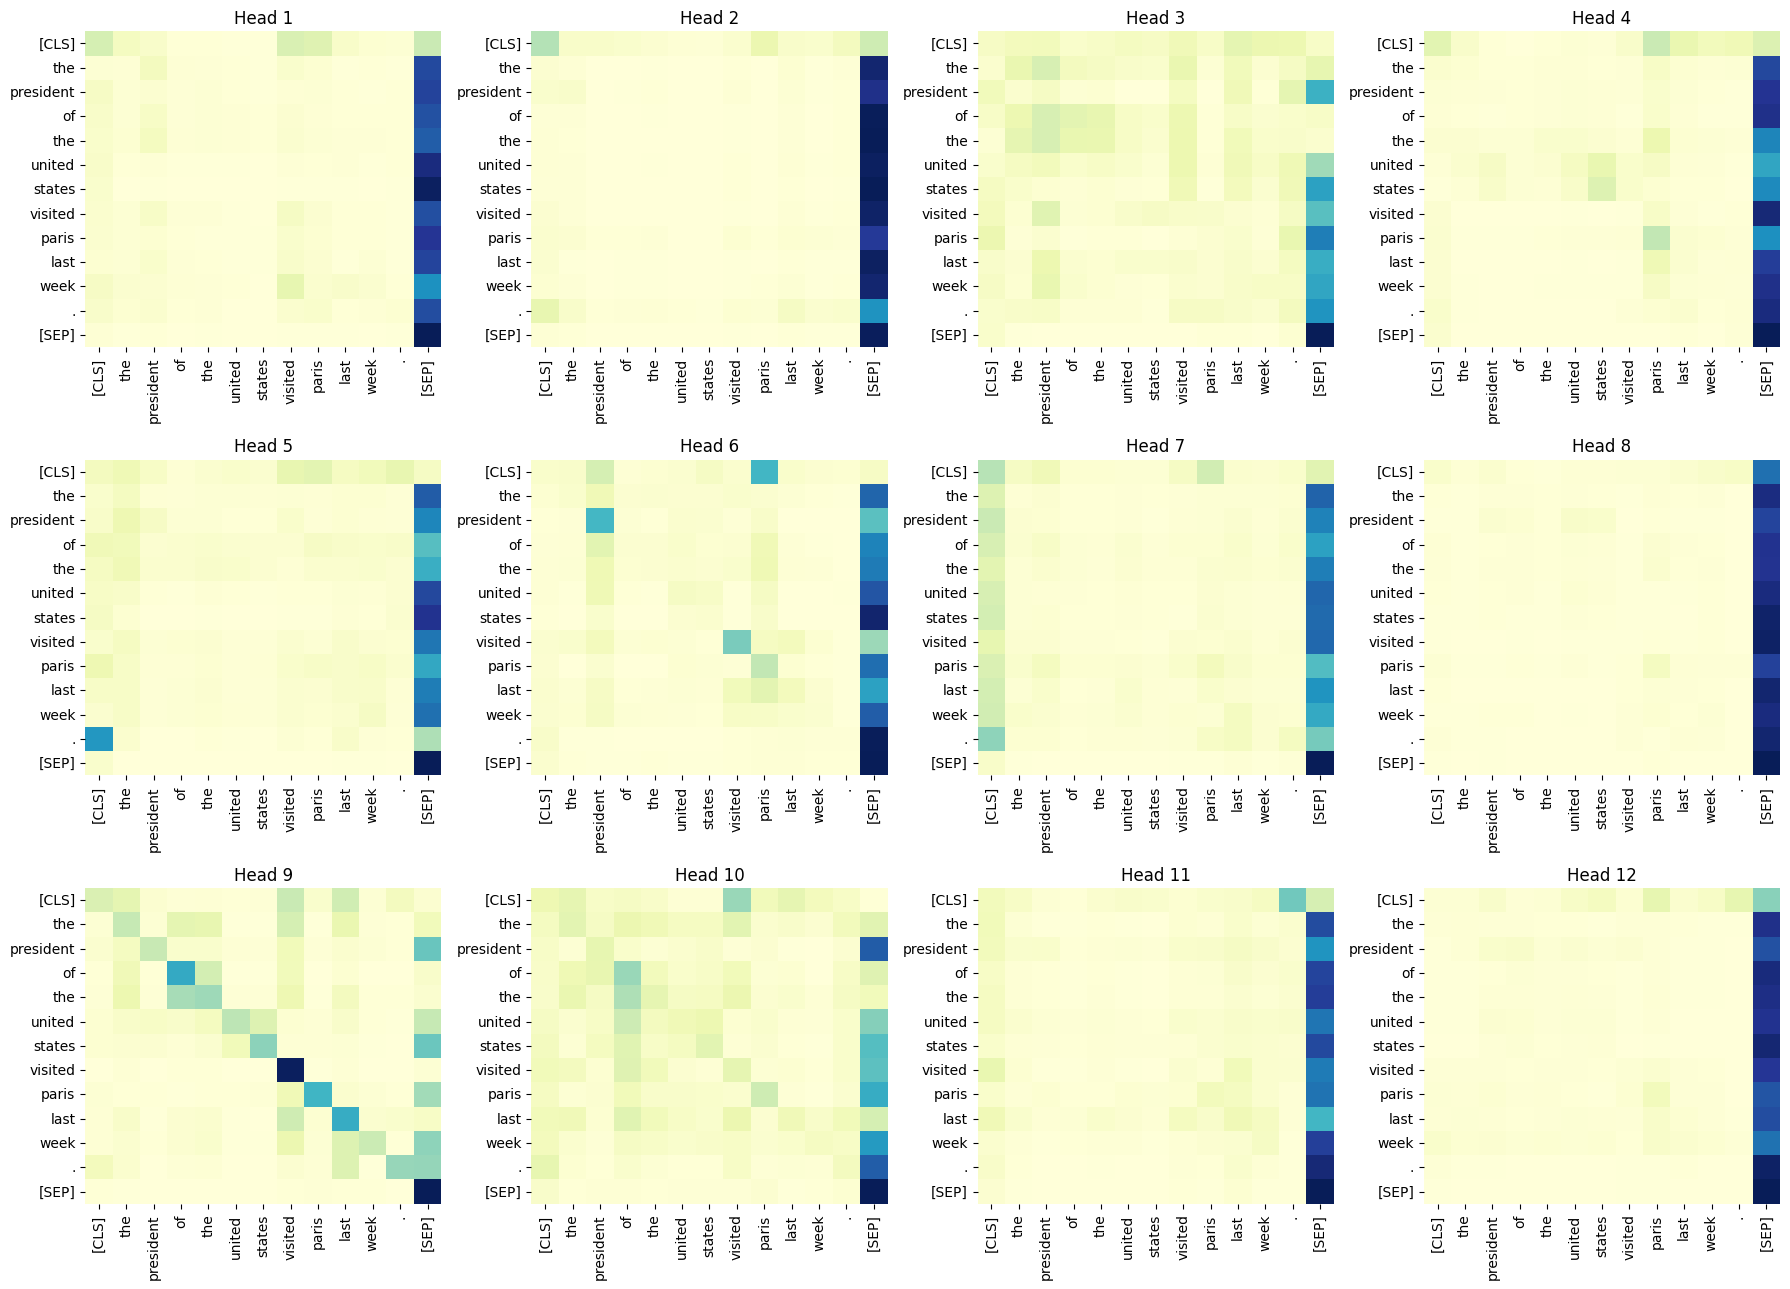

In [22]:
def analyze_multihead_attention(model, tokenizer, text):
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)
    attention = outputs.attentions[-1][0].cpu().numpy()   # (12 head, query, key)
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    num_heads = attention.shape[0]
    fig, axs = plt.subplots(3, 4, figsize=(18, 13))       # 12 panel untuk 12 head
    axs = axs.ravel()
    for i in range(num_heads):
        sns.heatmap(attention[i], xticklabels=tokens, yticklabels=tokens, ax=axs[i],
                    cmap="YlGnBu", cbar=False)
        axs[i].set_title(f"Head {i+1}")
    plt.tight_layout()
    plt.show()
    return attention, tokens


text = "The president of the United States visited Paris last week."
mh_attention, mh_tokens = analyze_multihead_attention(bert, tokenizer, text)

Cerita 16.1 berulang: hampir setiap panel punya kolom gelap di ujung kanan, `[SEP]`. Head 9 pengecualian paling jelas, dengan pola diagonal: tiap kata terutama memandang dirinya sendiri atau tetangganya.

In [23]:
received_by_head = mh_attention.mean(axis=1)    # (head, key): rata-rata atensi yang diterima tiap token
sep_share = received_by_head[:, -1]
word_share = received_by_head[:, 1:-2].sum(axis=1)
favorite = [mh_tokens[i] for i in received_by_head.argmax(axis=1)]

print(f"head yang paling banyak memandang [SEP]: {favorite.count('[SEP]')} dari {len(favorite)}")
print(f"porsi atensi ke [SEP] per head: {sep_share.min():.0%} sampai {sep_share.max():.0%}")
most_wordy = np.argsort(-word_share)[:3]
print("tiga head yang paling banyak memandang kata kalimat:",
      ", ".join(f"head {h + 1} ({word_share[h]:.0%})" for h in most_wordy))

head yang paling banyak memandang [SEP]: 12 dari 12
porsi atensi ke [SEP] per head: 24% sampai 85%
tiga head yang paling banyak memandang kata kalimat: head 9 (69%), head 10 (54%), head 3 (50%)


Token favorit **semua 12 head** adalah `[SEP]`, dengan porsi 24% sampai 85%. Hanya head 9, 10, dan 3 yang memberi kata-kata kalimat separuh atensinya atau lebih.

Jadi, membandingkan "spesialisasi" dari heatmap lapisan terakhir sebagian besar berarti membandingkan variasi dari satu perilaku: memarkir atensi. Head terspesialisasi memang ada (Clark dkk., 2019), tetapi ditemukan lewat pengukuran pada ribuan kalimat berlabel, bukan dengan menatap satu heatmap.

### Under the hood (UTH-3): apakah atensi menunjuk kata yang menentukan prediksi?

Pertanyaan yang kita tunda di 16.1 kini bisa diuji, karena kita punya model yang membuat prediksi (`clf`) dan metode atribusi yang bisa dicek (IG). Ujinya **uji penghapusan**: minta tiap metode menunjuk 20% token terpenting, ganti token-token itu dengan `[MASK]`, lalu ukur turunnya keyakinan model pada tebakannya.

Pesertanya:

- **atensi `[CLS]` lapisan 12** dari `clf`, karena vektor `[CLS]` yang dibaca kepala klasifikasi
- **attention rollout** (Abnar & Zuidema, 2020): atensi semua lapisan dikalikan berurutan
- **gradient x input**: gradien di satu titik saja, ibarat IG tanpa jalur
- **IG** dari 16.3, dan **skor acak** sebagai kontrol

Pembandingnya **oklusi**: tutup satu token dengan `[MASK]`, catat turunnya keyakinan, ulangi untuk tiap token. Karena memakai gangguan yang sama dengan uji ini, oklusi wajar unggul.

In [24]:
@torch.no_grad()
def prob_of_class(batch_ids, enc, pred_class):
    """p(kelas prediksi) untuk sekumpulan versi kalimat yang sebagian tokennya diganti."""
    n = len(batch_ids)
    logits = clf(input_ids=batch_ids, attention_mask=enc["attention_mask"].expand(n, -1),
                 token_type_ids=enc["token_type_ids"].expand(n, -1)).logits
    return F.softmax(logits, -1)[:, pred_class].cpu().numpy()


def attention_rollout(layer_attentions):
    """Abnar & Zuidema (2020): tambahkan jalur residual, lalu kalikan atensi antar-lapisan."""
    n = layer_attentions.shape[-1]
    rollout = torch.eye(n)
    for layer_att in layer_attentions:
        mixed = 0.5 * layer_att + 0.5 * torch.eye(n)
        rollout = (mixed / mixed.sum(-1, keepdim=True)) @ rollout
    return rollout


def grad_x_input(enc, pred_class):
    """Gradien logit terhadap embedding, dikali selisih embedding input dan [PAD]: IG dengan satu titik."""
    embed = clf.bert.embeddings.word_embeddings
    x = embed(enc["input_ids"]).detach().requires_grad_(True)
    logit = clf(inputs_embeds=x, attention_mask=enc["attention_mask"],
                token_type_ids=enc["token_type_ids"]).logits[0, pred_class]
    grad = torch.autograd.grad(logit, x)[0]
    x_pad = embed(torch.full_like(enc["input_ids"], tokenizer.pad_token_id)).detach()
    return ((x.detach() - x_pad) * grad).sum(-1)[0].cpu().numpy()


def importance_scores(sentence, rng):
    """Skor pentingnya tiap token kata menurut lima metode, plus oklusi sebagai patokan."""
    enc = tokenizer(sentence, return_tensors="pt").to(DEVICE)
    word_idx = np.arange(1, enc["input_ids"].shape[1] - 1)
    with torch.no_grad():
        out = clf(**enc, output_attentions=True)
    probs = F.softmax(out.logits, -1)[0].cpu().numpy()
    pred_class = int(probs.argmax())
    att = torch.stack(out.attentions)[:, 0].mean(1).cpu()   # (lapisan, query, key), rata-rata 12 head

    occluded = enc["input_ids"].repeat(len(word_idx), 1)    # baris ke-i: token kata ke-i diganti [MASK]
    rows = torch.arange(len(word_idx), device=DEVICE)
    occluded[rows, torch.as_tensor(word_idx, device=DEVICE)] = tokenizer.mask_token_id
    scores = {
        "atensi [CLS] L12": att[-1, 0].numpy()[word_idx],
        "attention rollout": attention_rollout(att)[0].numpy()[word_idx],
        "gradient x input": grad_x_input(enc, pred_class)[word_idx],
        "integrated gradients": integrated_gradients(clf, tokenizer, sentence, pred_class)[0][word_idx],
        "acak (kontrol)": rng.random(len(word_idx)),
        "oklusi (patokan)": probs[pred_class] - prob_of_class(occluded, enc, pred_class),
    }
    return enc, word_idx, pred_class, probs[pred_class], scores

In [25]:
clf.eval()
rng = np.random.default_rng(0)
uth3_sentences = [s.strip() for s in sst_val.shuffle(seed=2).select(range(150))["sentence"]]
drops = {}
start = time.time()
for sentence in uth3_sentences:
    enc, word_idx, pred_class, p_pred, scores = importance_scores(sentence, rng)
    n_delete = max(1, round(0.2 * len(word_idx)))       # 20% token kata teratas
    versions = []
    for score in scores.values():
        top = torch.as_tensor(word_idx[np.argsort(-score)[:n_delete]], device=DEVICE)
        version = enc["input_ids"].clone()
        version[0, top] = tokenizer.mask_token_id
        versions.append(version)
    p_after = prob_of_class(torch.cat(versions), enc, pred_class)
    for name, p in zip(scores, p_after):
        drops.setdefault(name, []).append(p_pred - p)

print(f"{len(uth3_sentences)} kalimat SST-2, {time.time() - start:.0f} detik")
print("turunnya p(kelas prediksi) bila 20% token teratas diganti [MASK]:\n")
for name, values in drops.items():
    values = np.array(values)
    boot = np.random.default_rng(0).choice(values, (2000, len(values))).mean(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])
    print(f"  {name:<22} {values.mean():.3f}   (CI95 {low:.3f} - {high:.3f})")

150 kalimat SST-2, 38 detik
turunnya p(kelas prediksi) bila 20% token teratas diganti [MASK]:

  atensi [CLS] L12       0.185   (CI95 0.161 - 0.211)
  attention rollout      0.146   (CI95 0.128 - 0.164)
  gradient x input       0.161   (CI95 0.143 - 0.180)
  integrated gradients   0.271   (CI95 0.246 - 0.295)
  acak (kontrol)         0.192   (CI95 0.173 - 0.212)
  oklusi (patokan)       0.356   (CI95 0.334 - 0.377)


Di run acuan, menghapus token pilihan atensi menurunkan keyakinan model rata-rata 0,141, misalnya dari 0,95 menjadi 0,81. Menghapus token *acak* menurunkannya 0,134. **CI95** (selang kepercayaan 95%, dihitung dengan bootstrap) adalah rentang nilai rata-rata sebenarnya yang masih sejalan dengan 150 kalimat ini, dan rentang keduanya (0,111-0,175 untuk atensi, 0,114-0,156 untuk acak) saling menutupi. **Atensi tidak lebih baik dari undian.**

Rollout malah di bawah acak (0,088), dan gradient x input (0,118) tak terbedakan dari acak. Pada model yang sudah yakin, gradien di satu titik bisa **jenuh**, nyaris nol karena keluaran tak lagi berubah walau input digeser sedikit. IG mengatasinya dengan merata-ratakan gradien sepanjang jalur: 0,272, dua kali kontrol acak, satu-satunya peserta yang jelas di atas undian. Patokan oklusi mencapai 0,361. Angka di output Anda bisa lain; yang perlu tetap terlihat adalah CI atensi yang bertumpuk dengan acak dan IG yang jelas di atas keduanya.

Itulah isi konkret peringatan buku bahwa atensi belum tentu menjelaskan keputusan.

## 16.5 Mechanistic interpretability

**Mechanistic interpretability** (MI) lebih ambisius dari skor pentingnya token: ia mencoba merekayasa balik *cara* model menghitung, komponen demi komponen. Alatnya dua. **Hook** membaca isi sebuah lapisan saat model memproses input (*forward pass*), dan **intervensi** mengubah satu komponen, misalnya menolkan satu neuron, lalu melihat perubahan pada keluaran.

Buku membangun kelas `InterpretableTransformer` kecil dengan tiga metode: membaca pola atensi, mencari neuron paling aktif, dan menolkan satu neuron.

> **Listing buku: `InterpretableTransformer`**
>
> ```python
> def hook(module, input, output):
>     nonlocal attention_weights
>     attention_weights = output[1]  # attention weights
> ...
> model = InterpretableTransformer(vocab_size=1000, d_model=256, nhead=8, num_layers=4)
> original, modified = model.intervention_study(input_ids, layer_idx=0, neuron_idx=42)
> ```
>
> - Kelasnya tak punya `forward`, jadi `self(x)` gagal (`NotImplementedError: ... missing the required "forward" function`).
> - Hook atensi selalu menangkap `None`, karena `nn.TransformerEncoderLayer` memanggil atensinya dengan `need_weights=False`.
> - `.eval()` tak pernah dipanggil pada model. Dropout membuat forward pass "asli" dan "dimodifikasi" sudah berbeda di semua 256 dimensi sebelum intervensi berpengaruh.
> - `intervention_study` mengembalikan keluaran lapisan yang dinolkan, bukan keluaran model, sehingga yang terukur hanyalah bahwa angka yang dinolkan menjadi nol.
> - Modelnya berbobot acak dengan input acak: belum ada perilaku untuk dijelaskan.

In [26]:
class InterpretableTransformer(nn.Module):
    def __init__(self, vocab_size, d_model, nhead, num_layers):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model, nhead, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers)
        self.fc = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        return self.fc(self.transformer(self.embedding(x)))

    def get_attention_patterns(self, x):
        """Extract attention weights from each layer"""
        x = self.embedding(x)
        attention_patterns = []
        for layer in self.transformer.layers:
            _, weights = layer.self_attn(x, x, x, need_weights=True)   # minta bobotnya secara eksplisit
            attention_patterns.append(weights.detach())
            x = layer(x)
        return attention_patterns

    def analyze_neuron_activations(self, x, layer_idx):
        """Analyze individual neuron activations in a specific layer"""
        activations = []

        def hook(module, input, output):
            activations.append(output.detach())

        handle = self.transformer.layers[layer_idx].register_forward_hook(hook)
        try:
            with torch.no_grad():
                self(x)
        finally:
            handle.remove()
        mean_activation = activations[0].mean(dim=(0, 1))   # Average across batch and sequence
        top_neurons = torch.topk(mean_activation, k=10)
        return top_neurons.indices, top_neurons.values

    @torch.no_grad()
    def intervention_study(self, x, layer_idx, neuron_idx):
        """Efek menolkan satu neuron pada KELUARAN model: KL dan porsi prediksi top-1 yang berubah."""
        original = F.log_softmax(self(x), dim=-1)

        def zero_neuron(module, input, output):
            modified = output.clone()
            modified[:, :, neuron_idx] = 0
            return modified

        handle = self.transformer.layers[layer_idx].register_forward_hook(zero_neuron)
        try:
            modified = F.log_softmax(self(x), dim=-1)
        finally:
            handle.remove()
        kl = (original.exp() * (original - modified)).sum(-1).mean().item()
        flipped = (original.argmax(-1) != modified.argmax(-1)).float().mean().item()
        return kl, flipped


def visualize_attention_pattern(attention_weights, tokens=None):
    """Visualize attention patterns"""
    plt.figure(figsize=(6, 5))
    plt.imshow(attention_weights[0].cpu(), cmap="viridis")
    if tokens is not None:
        plt.xticks(range(len(tokens)), tokens, rotation=45)
        plt.yticks(range(len(tokens)), tokens)
    plt.colorbar()
    plt.title("Attention Pattern")
    plt.show()

Kelas di atas mempertahankan struktur buku dengan empat perubahan: `forward` ditambahkan, bobot atensi diminta eksplisit (`need_weights=True`), intervensi diukur pada **keluaran model**, dan model dipakai dalam mode eval.

Model mainan ini kecil, jadi tetap di CPU, dan angkanya bisa dicocokkan langsung dengan narasi. Untuk tiap posisi input, ia mengeluarkan distribusi tebakan atas 1.000 token, dan "neuron" (seperti di buku) berarti satu dari 256 dimensi keluaran sebuah lapisan. Efek menolkannya diukur dengan **KL divergence**, yaitu seberapa jauh distribusi tebakan bergeser (0 berarti tak berubah), plus porsi posisi yang tebakan teratasnya berganti.

bentuk pola atensi per lapisan: [(1, 20, 20), (1, 20, 20), (1, 20, 20), (1, 20, 20)]
10 neuron teratas lapisan 0: [183, 218, 157, 132, 239, 170, 70, 98, 66, 25]
menolkan neuron 42 lapisan 0: KL keluaran 2.1e-04, prediksi berubah di 0% posisi


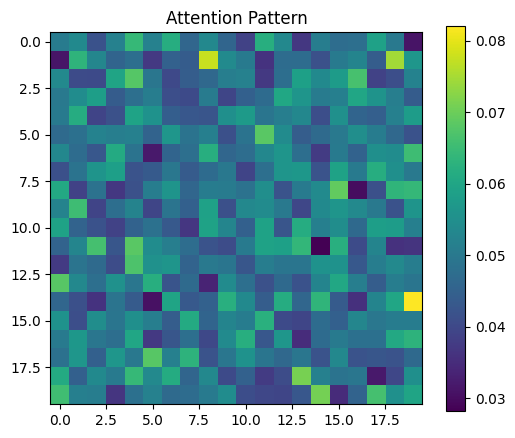

In [27]:
torch.manual_seed(16)
# model mainan sengaja tetap di CPU: kecil, dan hasil acaknya sama di semua perangkat
model = InterpretableTransformer(vocab_size=1000, d_model=256, nhead=8, num_layers=4).eval()
input_ids = torch.randint(0, 1000, (1, 20))   # Batch size 1, sequence length 20

attention_patterns = model.get_attention_patterns(input_ids)
top_neurons, activation_values = model.analyze_neuron_activations(input_ids, layer_idx=0)
kl, flipped = model.intervention_study(input_ids, layer_idx=0, neuron_idx=42)

print("bentuk pola atensi per lapisan:", [tuple(p.shape) for p in attention_patterns])
print("10 neuron teratas lapisan 0:", top_neurons.tolist())
print(f"menolkan neuron 42 lapisan 0: KL keluaran {kl:.1e}, prediksi berubah di {flipped:.0%} posisi")
visualize_attention_pattern(attention_patterns[0])

Perkakasnya kini bekerja: pola atensi 20 x 20 per lapisan, sepuluh neuron teratas, dan efek menolkan neuron 42 (KL hanya 0,00021, dan tak satu pun tebakan berganti).

Tapi lihat skala heatmap-nya: hanya 0,03 sampai 0,08, di sekitar 1/20 = 0,05. Setiap token memandang 20 token dengan bobot hampir sama. Adakah yang perlu dijelaskan dari model ini?

In [28]:
with torch.no_grad():
    probs = F.softmax(model(input_ids), dim=-1)
entropy = -(probs * probs.log()).sum(-1).mean().item()
kl_all = np.array([model.intervention_study(input_ids, 0, j)[0] for j in range(256)])

print(f"entropi keluaran {entropy:.3f} nats; distribusi seragam atas 1.000 token = {np.log(1000):.3f}")
print(f"probabilitas tebakan teratas rata-rata {probs.max(-1).values.mean():.4f} (seragam = 0.0010)")
print(f"neuron 42 berperingkat {int((kl_all > kl_all[42]).sum()) + 1} dari 256 menurut efek pada keluaran")

entropi keluaran 6.737 nats; distribusi seragam atas 1.000 token = 6.908
probabilitas tebakan teratas rata-rata 0.0057 (seragam = 0.0010)
neuron 42 berperingkat 252 dari 256 menurut efek pada keluaran


Tidak. **Entropi** mengukur seberapa rata sebuah distribusi; distribusi seragam atas 1.000 token punya entropi ln 1000 = 6,908 nats (satuan logaritma natural). Keluaran model ini 6,737, nyaris seragam, dan tebakan teratasnya rata-rata hanya berpeluang 0,0057. Neuron 42 pun tidak istimewa: peringkat 252 dari 256.

Pola dari model seperti ini adalah sifat inisialisasinya, bukan mekanisme. **MI menjawab bagaimana model melakukan sesuatu, jadi modelnya harus lebih dulu melakukan sesuatu.**

### Under the hood (UTH-4): mekanisme yang nyata, induction head di GPT-2

Ambil perilaku yang jelas pada model sungguhan: **menyalin dari konteks**. Kalau teks pernah memuat "Harry Potter", setelah "Harry" muncul lagi model cenderung menebak "Potter". Perilaku ini paling mudah diukur pada model yang menebak token berikutnya, jadi kita beralih ke GPT-2 (12 lapisan x 12 head). Mekanismenya disebut **induction head** (Elhage dkk., 2021; Olsson dkk., 2022): saat bertemu token yang pernah muncul, head ini memandang token *sesudah* kemunculan sebelumnya lalu menyalinnya.

Ujinya: 16 urutan berisi 50 token acak yang ditulis dua kali berturut-turut. Salinan pertama mustahil ditebak; salinan kedua bisa ditebak sempurna oleh model yang tahu cara menyalin. **Loss** adalah rata-rata "keterkejutan" model per token dalam nats, dan $e^{-\text{loss}}$ adalah peluang rata-rata (geometrik) yang diberikan model kepada token yang benar.

In [29]:
from transformers import GPT2LMHeadModel

gpt2 = GPT2LMHeadModel.from_pretrained("gpt2", attn_implementation="eager").to(DEVICE).eval()
SEQ_LEN, N_SEQ = 50, 16
random_tokens = torch.randint(1000, 30000, (N_SEQ, SEQ_LEN), generator=torch.Generator().manual_seed(0))
bos = torch.full((N_SEQ, 1), gpt2.config.bos_token_id)
repeated = torch.cat([bos, random_tokens, random_tokens], dim=1).to(DEVICE)   # [<|endoftext|>, a1..a50, a1..a50]


def loss_per_copy(logits, tokens):
    """Rata-rata loss (nats) menebak a2..a50 di salinan pertama dan di salinan kedua."""
    logp = F.log_softmax(logits[:, :-1].float(), dim=-1)
    nll = -logp.gather(-1, tokens[:, 1:, None])[..., 0]
    return nll[:, 1:SEQ_LEN].mean().item(), nll[:, SEQ_LEN + 1:].mean().item()


with torch.no_grad():
    out = gpt2(repeated, output_attentions=True)
loss_first, loss_second = loss_per_copy(out.logits, repeated)
gpt2_attentions = out.attentions   # dipakai sel skor induksi
del out
print(f"loss salinan pertama {loss_first:.3f} nats (peluang token benar sekitar {np.exp(-loss_first):.1e})")
print(f"loss salinan kedua   {loss_second:.3f} nats (peluang token benar sekitar {np.exp(-loss_second):.2f})")
print(f"pembanding, tebakan seragam atas 50.257 token: ln(50257) = {np.log(50257):.2f} nats")

loss salinan pertama 12.876 nats (peluang token benar sekitar 2.6e-06)
loss salinan kedua   0.204 nats (peluang token benar sekitar 0.82)
pembanding, tebakan seragam atas 50.257 token: ln(50257) = 10.82 nats


Loss salinan pertama 12,876 nats, lebih buruk dari tebakan seragam (10,82): GPT-2 yakin tetapi salah. Di salinan kedua loss anjlok ke 0,204, artinya token yang benar mendapat peluang sekitar 0,82. **GPT-2 menyalin dari konteks.**

Head mana yang melakukannya? Untuk tiap head kita hitung **skor induksi**: porsi atensi dari token di salinan kedua yang jatuh tepat pada token sesudah kembarannya di salinan pertama. Head induksi sejati mendekati 1.

skor induksi tertinggi (lapisan.head, dihitung mulai dari 0): 5.5 = 0.94, 6.9 = 0.92, 7.10 = 0.92, 5.1 = 0.91, 7.2 = 0.84, 10.1 = 0.54
median skor 144 head: 0.006


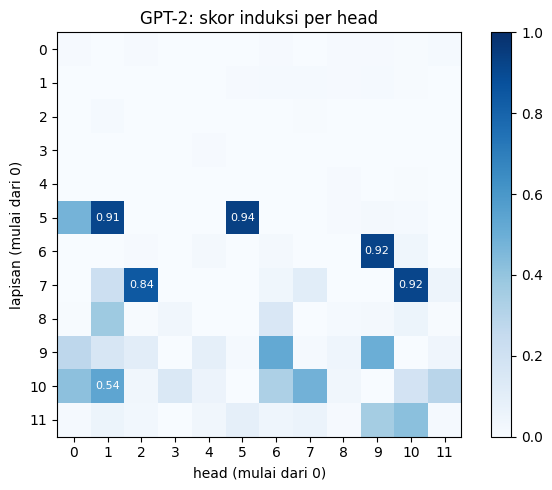

In [30]:
# skor induksi: dari token a_k di salinan kedua, berapa atensi ke token SESUDAH kemunculan pertamanya (a_k+1)?
queries = torch.arange(SEQ_LEN + 1, 2 * SEQ_LEN + 1, device=DEVICE)
keys = queries - SEQ_LEN + 1
score = np.stack([layer_att[:, :, queries, keys].float().mean(dim=(0, 2)).cpu().numpy()
                  for layer_att in gpt2_attentions])                   # (12 lapisan, 12 head)
ranked_heads = np.column_stack(np.unravel_index(np.argsort(-score, axis=None), score.shape))

top_six = ", ".join(f"{layer}.{head} = {score[layer, head]:.2f}" for layer, head in ranked_heads[:6])
print("skor induksi tertinggi (lapisan.head, dihitung mulai dari 0):", top_six)
print(f"median skor 144 head: {np.median(score):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(score, cmap="Blues", vmin=0, vmax=1)
for layer, head in ranked_heads[:6]:
    ax.text(head, layer, f"{score[layer, head]:.2f}", ha="center", va="center", fontsize=8, color="white")
ax.set_xlabel("head (mulai dari 0)")
ax.set_ylabel("lapisan (mulai dari 0)")
ax.set_xticks(range(12))
ax.set_yticks(range(12))
ax.set_title("GPT-2: skor induksi per head")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

Label `lapisan.head` di output dihitung mulai dari 0 (di 16.4 kita mulai dari 1), jadi `5.5` adalah head keenam di lapisan keenam. Lima head menonjol: `5.5` (0,94), `6.9` dan `7.10` (0,92), `5.1` (0,91), serta `7.2` (0,84). Peringkat keenam, `10.1`, sudah jauh di bawah (0,54), dan median 144 head hanya 0,006.

Tapi pola atensi baru **hipotesis**. Buktinya harus kausal, lewat **ablasi**: nolkan keluaran head-head itu, lihat apakah kemampuan menyalin hilang, lalu bandingkan dengan menolkan head acak sebanyak yang sama, mulai dari 2 head, lalu 4, lalu 6.

In [31]:
def ablate(heads_to_zero):
    """Nolkan keluaran head terpilih (irisan 64 dimensi masukan c_proj), lalu ukur loss per salinan."""
    by_layer = {}
    for layer, head in heads_to_zero:
        by_layer.setdefault(int(layer), []).append(int(head))
    hooks = []
    for layer, heads in by_layer.items():
        def zero_heads(module, args, heads=heads):
            z = args[0].clone()
            for head in heads:
                z[..., head * 64:(head + 1) * 64] = 0
            return (z,)
        hooks.append(gpt2.transformer.h[layer].attn.c_proj.register_forward_pre_hook(zero_heads))
    try:
        with torch.no_grad():
            logits = gpt2(repeated).logits
    finally:
        for hook in hooks:
            hook.remove()
    return loss_per_copy(logits, repeated)


def random_heads(k, rng):
    """k head acak di luar 6 head induksi teratas: kontrol berukuran sama."""
    pool = ranked_heads[6:]
    return pool[rng.choice(len(pool), k, replace=False)]


rng = np.random.default_rng(0)
print(f"{'dinolkan':<24} {'loss salinan 2':>14}   head acak sebanyak itu (10 undian)")
print(f"{'tidak ada':<24} {loss_second:>14.3f}")
for k in (2, 4, 6):
    _, induction_loss = ablate(ranked_heads[:k])
    random_losses = []
    for _ in range(10):
        _, loss = ablate(random_heads(k, rng))
        random_losses.append(loss)
    print(f"{f'{k} head induksi teratas':<24} {induction_loss:>14.3f}   "
          f"rata-rata {np.mean(random_losses):.3f}, maks {np.max(random_losses):.3f}")

dinolkan                 loss salinan 2   head acak sebanyak itu (10 undian)
tidak ada                         0.204
2 head induksi teratas            0.386   rata-rata 0.279, maks 0.474
4 head induksi teratas            1.733   rata-rata 0.426, maks 0.913
6 head induksi teratas            6.102   rata-rata 0.424, maks 1.260


Menolkan 2 head induksi menaikkan loss hanya ke 0,386, masih dalam rentang head acak (maksimum 0,474): head induksi lain menutupi kekurangannya, jadi **mekanismenya redundan**. Dengan 6 head, loss melonjak ke 6,102, sementara 6 head acak rata-rata hanya 0,424. Peluang token yang tinggal disalin turun dari 0,82 ke 0,002.

Inilah langkah MI buku dalam bentuk lengkapnya: model terlatih, pola sebagai hipotesis, intervensi pada keluaran, dan kontrol acak. Klaim yang aman: head-head ini **diperlukan** untuk menyalin, belum tentu *hanya* menyalin.

## 16.6 Kinerja lawan interpretabilitas: distilasi

Bagian penutup buku membahas tarik-menarik antara model besar yang akurat dan model yang lebih mudah dipahami. Jalan tengah pertamanya **distilasi**: model kecil (**murid**) dilatih meniru model besar (**guru**) lewat **label lunak**, yaitu distribusi probabilitas guru. "88% positif" mengajarkan lebih banyak daripada sekadar "positif", dan **temperature** T > 1 melunakkannya lagi agar perbedaan kecil antar-kelas ikut terlihat.

> **Listing buku: `distill_bert`**
>
> ```python
> teacher_outputs = teacher_model(inputs)
> ...
> teacher_model = BertForSequenceClassification.from_pretrained("bert-base-uncased")
> texts = ["This movie was great!", "I didn't like the book.", ...]
> ```
>
> - `teacher_model(inputs)` dan placeholder `...`: sama seperti di 16.1 dan 16.2.
> - Gurunya BERT berkepala klasifikasi acak, jenis model yang di 16.3 kalah dari tebakan mayoritas. Yang bisa ia wariskan hanyalah bias.
>
> Versi di bawah memakai guru `clf` dan memproses 16 kalimat sekaligus alih-alih satu. Loss-nya dikalikan T² (Hinton dkk., 2015) supaya temperature tidak ikut mengecilkan gradien.

In [32]:
from transformers import DistilBertForSequenceClassification

forget("bert", "cat_attentions", "gpt2", "gpt2_attentions", "repeated")   # model 16.1-16.4 dan GPT-2 tak dipakai lagi


def distill_bert(teacher_model, student_model, tokenizer, texts, temperature=2.0, batch_size=16, lr=5e-5):
    teacher_model.eval()
    student_model.train()
    optimizer = torch.optim.Adam(student_model.parameters(), lr=lr)
    loss_fn = torch.nn.KLDivLoss(reduction="batchmean")
    for start in range(0, len(texts), batch_size):
        inputs = tokenizer(texts[start:start + batch_size], return_tensors="pt", padding=True,
                           truncation=True, max_length=128).to(teacher_model.device)
        with torch.no_grad():
            teacher_logits = teacher_model(**inputs).logits / temperature
        inputs.pop("token_type_ids")   # DistilBERT tidak memakai segment embedding
        student_logits = student_model(**inputs).logits / temperature
        loss = loss_fn(torch.log_softmax(student_logits, dim=-1),
                       torch.softmax(teacher_logits, dim=-1)) * temperature ** 2
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    optimizer.zero_grad(set_to_none=True)   # lepaskan gradien langkah terakhir dari memori
    return student_model.eval()


torch.manual_seed(0)
student = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased").to(DEVICE)
distill_texts = [s.strip() for s in sst_train.shuffle(seed=1).select(range(2000))["sentence"]]
start = time.time()
student = distill_bert(clf, student, tokenizer, distill_texts)
sync()
free_memory()
print(f"distilasi 2.000 kalimat tanpa label di {DEVICE}: {time.time() - start:.0f} detik")

distilasi 2.000 kalimat tanpa label di cuda: 13 detik


Murid tidak pernah melihat label SST-2: pengetahuan sentimennya seluruhnya datang dari label lunak guru, di atas pengetahuan bahasa dari pra-latih DistilBERT. Sekarang keduanya dibandingkan pada 872 kalimat validasi.

In [33]:
def timed_predict(model):
    predict_proba(model, VAL_TEXTS[:64])   # pemanasan: panggilan GPU pertama selalu lebih lambat
    sync()
    start = time.time()
    probs = predict_proba(model, VAL_TEXTS)
    sync()
    return probs, time.time() - start


p_teacher, t_teacher = timed_predict(clf)
p_student, t_student = timed_predict(student)
n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6

print(f"{'':<20} {'parameter':>10} {'lapisan':>8} {'akurasi':>8} {'waktu 872 kalimat':>18}")
print(f"{'guru (BERT)':<20} {n_params(clf):>9.1f}M {clf.config.num_hidden_layers:>8} "
      f"{np.mean(p_teacher.argmax(1) == VAL_LABELS):>8.3f} {t_teacher:>17.1f}s")
print(f"{'murid (DistilBERT)':<20} {n_params(student):>9.1f}M {student.config.n_layers:>8} "
      f"{np.mean(p_student.argmax(1) == VAL_LABELS):>8.3f} {t_student:>17.1f}s")
print(f"murid sepakat dengan guru di {np.mean(p_student.argmax(1) == p_teacher.argmax(1)):.1%} kalimat")
if DEVICE.type == "cuda":
    print(f"puncak memori GPU sepanjang notebook: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

                      parameter  lapisan  akurasi  waktu 872 kalimat
guru (BERT)              109.5M       12    0.861               2.8s
murid (DistilBERT)        67.0M        6    0.857               1.4s
murid sepakat dengan guru di 91.1% kalimat
puncak memori GPU sepanjang notebook: 2.9 GB


Di run acuan, murid dengan separuh lapisan dan sekitar 60% parameter guru (67,0 lawan 109,5 juta) mencapai akurasi 0,841, 3,4 poin di bawah guru (0,875), dan memproses 872 kalimat sekitar dua kali lebih cepat di CPU; di GPU kedua waktu jauh lebih kecil sehingga rasionya bisa lain, jadi lihat kolom waktu di output Anda. Tapi keduanya hanya sepakat di 88,8% kalimat: murid berbeda tebakan pada sekitar 1 dari 9 kalimat. **Murid meniru perilaku guru secara garis besar, bukan menyalinnya.**

Klaim buku bahwa model hasil distilasi lebih mudah dipahami belum terbukti di sini. Murid tetap transformer dengan 6 lapisan x 12 head, dan tak satu pun perkakas bab ini diukur ulang padanya. **Distilasi memberi efisiensi, tetapi interpretabilitas harus diukur tersendiri.** Baris terakhir output, khusus GPU, adalah puncak memori GPU sepanjang notebook; bandingkan dengan memori bebas di sel setup.

## Ringkasan

Angka di bawah berasal dari run acuan CPU.

- **Atensi** lapisan 12 sebagian besar parkir di `[SEP]`, dan menghapus token yang paling diperhatikan tak lebih berpengaruh daripada menghapus token acak (0,141 lawan 0,134).
- **Probing** baru bermakna di samping kontrol: urutan kata sungguh dipelajari (0,85, BERT acak 0,49), panjang kalimat tidak.
- **Integrated gradients** di ruang embedding satu-satunya dari lima metode yang jelas mengalahkan undian (0,272), tetapi jawabannya bergantung pada baseline dan pada model yang dijelaskan.
- **Mechanistic interpretability** butuh model yang sungguh melakukan sesuatu: pada GPT-2, ablasi membuktikan induction head secara kausal dan memperlihatkan redundansinya.
- **Distilasi** menukar 3,4 poin akurasi dengan inferensi yang lebih cepat; interpretabilitasnya belum diukur.

Listing buku tersandung di empat tempat yang sama berulang kali: `model(inputs)` alih-alih `model(**inputs)`, placeholder `...` sebagai data, kepala klasifikasi yang tak pernah dilatih, dan bobot atensi yang tak pernah dikembalikan. Periksa keempatnya dulu setiap kali memakai listing interpretabilitas lain.

**What comes next.** Chapter 17 membahas fairness dan bias. Dua alat dari bab ini langsung terpakai di sana: uji penghapusan, untuk memeriksa apakah penjelasan setia pada model, dan kontrol acak, untuk memeriksa apakah temuan memang milik model terlatih.